# Task for session2_cont and session3: 
## Edge-Preserving Denoising Filters & Feature Matching

**Instructions:**  
**please dont use .py to solve this task, just use tasks2.ipynb and edit the cells.**
- After forking the [SkyXperts-Vision-Course repo](https://github.com/ffathy-tdx/SkyXperts-Vision-Course) on GitHub. (you should have already dont this in the last session & uploaded task1)
- Go to your fork of the repo on GitHub.
- At the top, look for a yellow box that says “This branch is X commits behind…”
- Click the Sync fork or Update branch button.
The new task will show up in your tasks/ folder.  
- Upload your task to your forked repo (like you've done with task1 before)
---

## 1. DoG, LoG, and Edge-Preserving Denoising Filters

**Task:**
- Briefly read the descriptions below, then apply each filter to `'sample.jpg'` (or any test image you choose).
- Compare the results visually and write your observations.

**Background:**
- **DoG (Difference of Gaussian):** Used for edge detection by subtracting two blurred versions of the image (with different Gaussian sigmas).
- **LoG (Laplacian of Gaussian):** Uses a single Gaussian blur followed by Laplacian to highlight regions of rapid intensity change (edges).
- **Edge-Preserving Denoising (Bilateral Filter):** Smooths image while preserving edges (unlike simple Gaussian blur). You've already used this at the end of task1.

---

Image used: generated demo image (sample.jpg was not found) | Shape: (480, 640)


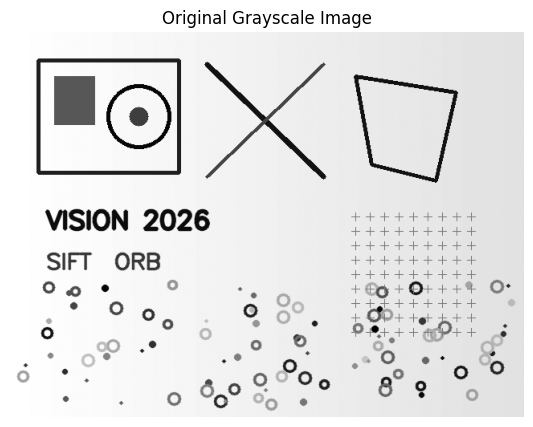

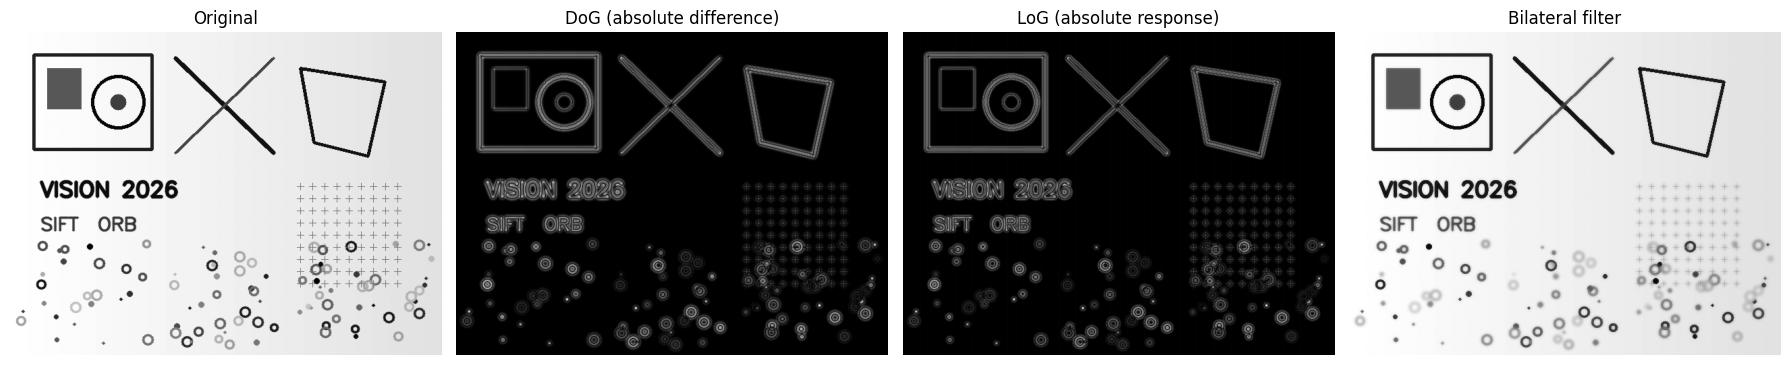

In [1]:
# Import required libraries
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# A reproducible fallback image is used only when sample.jpg is not in the
# notebook's working directory. Replace it with your own sample.jpg anytime.
def make_demo_image(width=640, height=480, seed=7):
    rng = np.random.default_rng(seed)
    canvas = np.full((height, width), 225, dtype=np.uint8)

    # Add a gentle background gradient.
    gradient = np.linspace(0, 25, width, dtype=np.uint8)
    canvas = np.clip(canvas.astype(np.int16) - gradient[None, :], 0, 255).astype(np.uint8)

    # Draw varied, distinctive shapes and lines to create useful features.
    cv2.rectangle(canvas, (35, 35), (210, 175), 45, 3)
    cv2.rectangle(canvas, (55, 55), (105, 115), 90, -1)
    cv2.circle(canvas, (160, 105), 38, 25, 4)
    cv2.circle(canvas, (160, 105), 12, 70, -1)
    cv2.line(canvas, (245, 40), (390, 180), 35, 5)
    cv2.line(canvas, (390, 40), (245, 180), 75, 3)
    cv2.polylines(canvas, [np.array([[430, 55], [555, 75], [530, 185], [450, 165]], dtype=np.int32)], True, 35, 4)
    cv2.putText(canvas, 'VISION 2026', (45, 245), cv2.FONT_HERSHEY_SIMPLEX, 1.05, 30, 3, cv2.LINE_AA)
    cv2.putText(canvas, 'SIFT  ORB', (45, 295), cv2.FONT_HERSHEY_SIMPLEX, 0.9, 65, 2, cv2.LINE_AA)

    # Add deterministic small circles, crosses, and textured patches.
    for _ in range(95):
        x = int(rng.integers(15, width - 15))
        y = int(rng.integers(315, height - 15))
        radius = int(rng.integers(2, 8))
        shade = int(rng.integers(20, 180))
        cv2.circle(canvas, (x, y), radius, shade, -1 if radius < 5 else 2, cv2.LINE_AA)
    for x in range(430, 590, 18):
        for y in range(230, 390, 18):
            cv2.line(canvas, (x - 5, y), (x + 5, y), 115, 1)
            cv2.line(canvas, (x, y - 5), (x, y + 5), 115, 1)
    return canvas


sample_path = Path('sample.jpg')
if sample_path.exists():
    img = cv2.imread(str(sample_path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError("sample.jpg exists but OpenCV could not read it. Check the image file.")
    image_source = "sample.jpg"
else:
    img = make_demo_image()
    image_source = "generated demo image (sample.jpg was not found)"

print(f"Image used: {image_source} | Shape: {img.shape}")

# Show the original grayscale image.
plt.figure(figsize=(7, 5))
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.title('Original Grayscale Image')
plt.show()

# 1) Difference of Gaussian (DoG): subtract two Gaussian-blurred images.
blur_sigma_1 = cv2.GaussianBlur(img, (0, 0), sigmaX=1.0)
blur_sigma_2 = cv2.GaussianBlur(img, (0, 0), sigmaX=2.0)
dog_signed = blur_sigma_1.astype(np.float32) - blur_sigma_2.astype(np.float32)
dog = cv2.normalize(np.abs(dog_signed), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 2) Laplacian of Gaussian (LoG): Gaussian smoothing followed by Laplacian.
smoothed = cv2.GaussianBlur(img, (0, 0), sigmaX=1.2)
log_signed = cv2.Laplacian(smoothed, cv2.CV_32F, ksize=3)
log = cv2.normalize(np.abs(log_signed), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 3) Bilateral filter: smooths similar intensities while keeping edges clearer.
bilateral = cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
images = [img, dog, log, bilateral]
titles = ['Original', 'DoG (absolute difference)', 'LoG (absolute response)', 'Bilateral filter']
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Answer (Q1):**

- **DoG** highlights fine intensity changes by subtracting two blur levels. It produces bright, narrow responses around many edges and small details; changing the two sigma values changes which details are emphasized.
- **LoG** first reduces small-scale noise with Gaussian blur, then uses the Laplacian to respond to rapid intensity changes. Its edge response is often sharper and can emphasize small details, but it may still react to noise if the smoothing is too weak.
- **Bilateral filtering** is different: it is a denoising/smoothing method, not an edge detector. It reduces noise in relatively uniform regions while keeping strong boundaries clearer than ordinary Gaussian blur.

**Overall:** DoG and LoG make edges/details stand out for later analysis, while the bilateral filter aims to produce a cleaner image without blurring important boundaries as much. The displayed DoG and LoG images use absolute, normalized responses so their strengths are easy to see.

## 2. Keypoints & Descriptors: SIFT vs. ORB

**Task:**
- Detect and plot keypoints on `'sample.jpg'` using SIFT and ORB.
- Compare the number and distribution of detected keypoints.

**Background:**
- **Keypoints:** Distinctive image points (corners/blobs) useful for matching.
- **Descriptors:** Vectors that describe local patches around keypoints for comparison/matching.

---

SIFT keypoints detected: 758 (showing up to 500)
ORB keypoints detected:  4366 (showing up to 500)


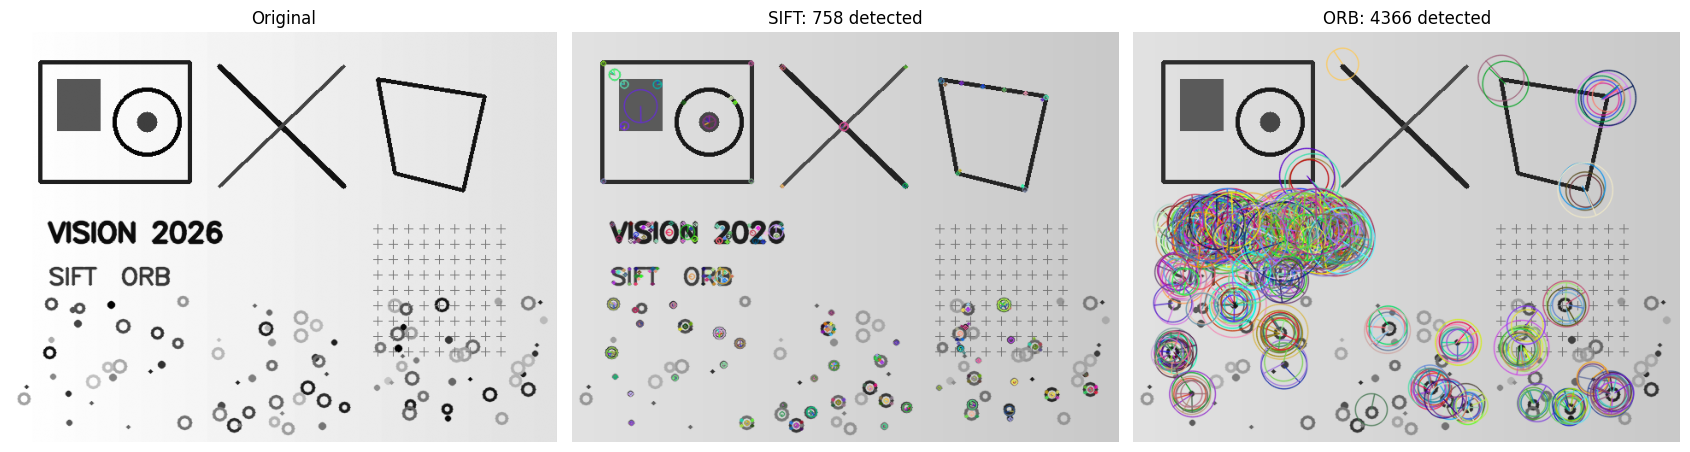

In [2]:
# Detect keypoints and descriptors with both algorithms.
# SIFT keeps all detected keypoints; ORB's high feature limit avoids an overly
# small default cap for this comparison.
sift = cv2.SIFT_create()
orb = cv2.ORB_create(nfeatures=5000)

kp_sift, des_sift = sift.detectAndCompute(img, None)
kp_orb, des_orb = orb.detectAndCompute(img, None)

# Draw the 500 strongest points from each detector so the plots remain readable.
# The printed counts below still use ALL detected keypoints.
kp_sift_display = sorted(kp_sift, key=lambda kp: kp.response, reverse=True)[:500]
kp_orb_display = sorted(kp_orb, key=lambda kp: kp.response, reverse=True)[:500]
sift_view = cv2.drawKeypoints(
    img, kp_sift_display, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
orb_view = cv2.drawKeypoints(
    img, kp_orb_display, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

print(f"SIFT keypoints detected: {len(kp_sift)} (showing up to {len(kp_sift_display)})")
print(f"ORB keypoints detected:  {len(kp_orb)} (showing up to {len(kp_orb_display)})")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Original')
axes[1].imshow(cv2.cvtColor(sift_view, cv2.COLOR_BGR2RGB))
axes[1].set_title(f'SIFT: {len(kp_sift)} detected')
axes[2].imshow(cv2.cvtColor(orb_view, cv2.COLOR_BGR2RGB))
axes[2].set_title(f'ORB: {len(kp_orb)} detected')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Answer (Q2):**

- **SIFT** detects distinctive local regions using scale-space extrema. Its keypoints can appear at different sizes, and the circles drawn in the visualization indicate their scale and orientation. SIFT is designed to be robust to changes in image scale and rotation.
- **ORB** uses FAST-based corner detection with an orientation component. Its keypoints are usually more corner-focused, and it is designed to be computationally efficient.
- The exact number depends on the image and detector settings. In this notebook, SIFT keeps all detected points and ORB is configured with a high maximum of 5,000. For readability, the plot displays only the 500 strongest points from each detector, while the printed counts include all detected points.

**In this image:** compare whether points cluster around text, corners, circles, and textured regions. Their locations differ because the algorithms define and rank distinctive points differently. Neither detector is guaranteed to return more points in every image; the distribution and usefulness of the points matter as much as the count.

## 3. Feature Matching with Descriptors

**Task:**
- Load a second image (e.g., `'sample2.jpg'`).
- Detect keypoints/descriptors using SIFT or ORB in both images.
- Match the features between the images using BFMatcher or FLANN.
- Plot the top matches.

**Background:**
- **Feature matching** helps recognize objects/scenes or estimate image transformations.

---

Second image used: transformed version of the first image (sample2.jpg was not found) | Shape: (480, 640)
Image 1: 758 keypoints | Image 2: 1035 keypoints
Good matches after Lowe's ratio test: 346
Geometrically consistent matches (RANSAC inliers): 319


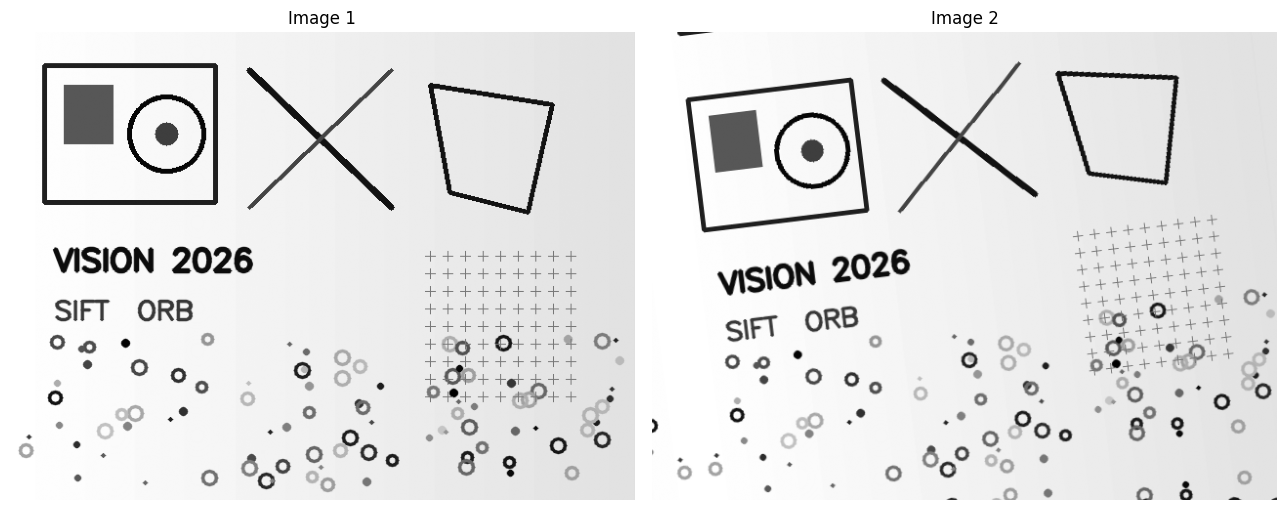

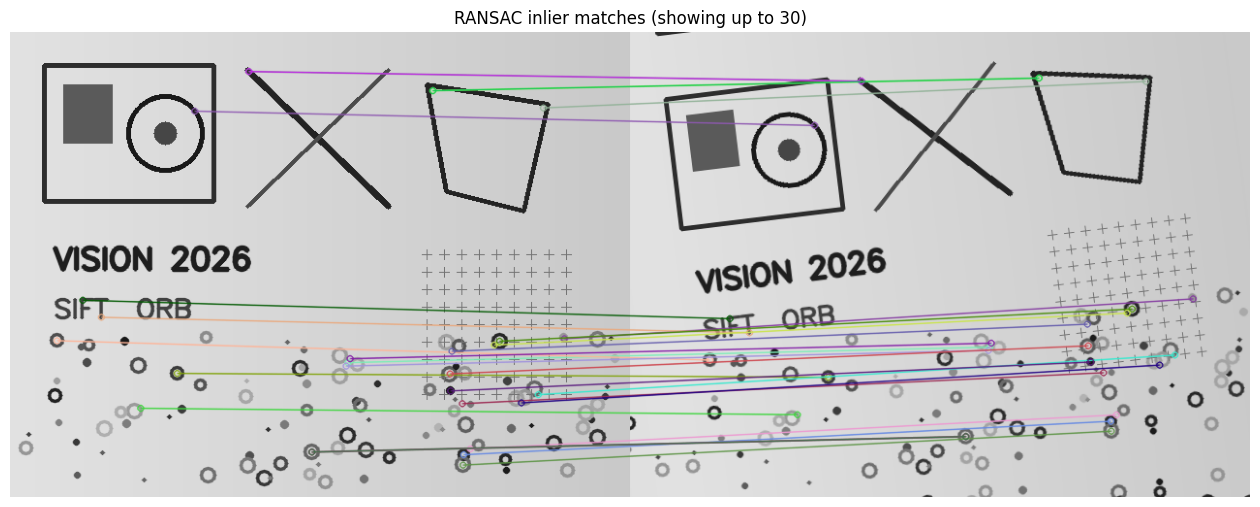

In [3]:
# Load a second image. If sample2.jpg is unavailable, create a transformed
# version of the first image so that the matching example can still run.
second_path = Path('sample2.jpg')
if second_path.exists():
    img2 = cv2.imread(str(second_path), cv2.IMREAD_GRAYSCALE)
    if img2 is None:
        raise ValueError("sample2.jpg exists but OpenCV could not read it. Check the image file.")
    second_source = "sample2.jpg"
else:
    height, width = img.shape
    transform = cv2.getRotationMatrix2D((width / 2, height / 2), 7, 0.96)
    transform[0, 2] += 12
    transform[1, 2] -= 8
    img2 = cv2.warpAffine(
        img, transform, (width, height),
        flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT
    )
    second_source = "transformed version of the first image (sample2.jpg was not found)"

print(f"Second image used: {second_source} | Shape: {img2.shape}")

# Detect SIFT keypoints/descriptors in both images.
kp1, des1 = sift.detectAndCompute(img, None)
kp2, des2 = sift.detectAndCompute(img2, None)
print(f"Image 1: {len(kp1)} keypoints | Image 2: {len(kp2)} keypoints")

# SIFT descriptors are floating-point vectors, so use the L2 distance.
bf = cv2.BFMatcher(cv2.NORM_L2)

if des1 is None or des2 is None or len(des1) < 2 or len(des2) < 2:
    print("Not enough descriptors were detected to perform KNN feature matching.")
    good_matches = []
    inlier_matches = []
else:
    # K-nearest-neighbor matching and Lowe's ratio test reduce ambiguous matches.
    knn_matches = bf.knnMatch(des1, des2, k=2)
    good_matches = [m for pair in knn_matches if len(pair) == 2
                    for m, n in [pair] if m.distance < 0.75 * n.distance]
    good_matches = sorted(good_matches, key=lambda match: match.distance)
    print(f"Good matches after Lowe's ratio test: {len(good_matches)}")

    # RANSAC checks whether matches agree with one geometric transformation.
    inlier_matches = []
    if len(good_matches) >= 4:
        src_points = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        dst_points = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        homography, inlier_mask = cv2.findHomography(
            src_points, dst_points, cv2.RANSAC, 5.0
        )
        if inlier_mask is not None:
            inlier_matches = [m for m, keep in zip(good_matches, inlier_mask.ravel()) if keep]
    print(f"Geometrically consistent matches (RANSAC inliers): {len(inlier_matches)}")

# Prefer geometrically consistent matches for the plot; otherwise show the
# best ratio-test matches. Limit the display to keep the figure readable.
matches_to_draw = inlier_matches if inlier_matches else good_matches
matches_to_draw = matches_to_draw[:30]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Image 1')
axes[1].imshow(img2, cmap='gray')
axes[1].set_title('Image 2')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

if matches_to_draw:
    match_image = cv2.drawMatches(
        img, kp1, img2, kp2, matches_to_draw, None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    plt.figure(figsize=(16, 7))
    plt.imshow(cv2.cvtColor(match_image, cv2.COLOR_BGR2RGB))
    label = 'RANSAC inlier matches' if inlier_matches else 'Best ratio-test matches'
    plt.title(f'{label} (showing up to {len(matches_to_draw)})')
    plt.axis('off')
    plt.show()
else:
    print("No reliable matches were found. Try images with shared visual content or use ORB/FLANN.")

**Answer (Q3):**

The strongest matches should connect similar local patterns in the two images. Some matches can still be incorrect, especially when an image contains repeated shapes or texture, when the images have little content in common, or when lighting, scale, rotation, or viewpoint changes are large.

The **Lowe ratio test** helps reject ambiguous matches by keeping a match only when its nearest descriptor is sufficiently better than the second-nearest one. The **RANSAC** step then keeps matches that agree with one shared geometric transformation, which removes many spatially inconsistent outliers. In the plot, the lines should mostly connect corresponding locations; any remaining incorrect lines are possible mismatches.

Matching can be improved by using images with overlapping content, adjusting the ratio threshold, checking more than one detector/descriptor (such as ORB), improving image quality, and using RANSAC to reject outliers. The number of good matches alone is not enough: their spatial consistency is important too.

**Bonus Task (Optional, for extra credit):**
- Try using different image preprocessing steps *before* edge detection or feature extraction.
    - For example:
        - Add noise to your image (e.g., Gaussian noise, salt-and-pepper noise).
        - Apply a sharpening filter to your image.
    - Then, run DoG, LoG, or any edge-preserving filter and observe the changes.
- **What to do:**
    - Show the results (images/plots) for at least one type of preprocessing + edge detection.
    - Briefly explain:
        - How does noise affect edge maps or keypoints?
        - Does sharpening make features easier or harder to detect/match?

**You can add your code and observations in the cells below.**


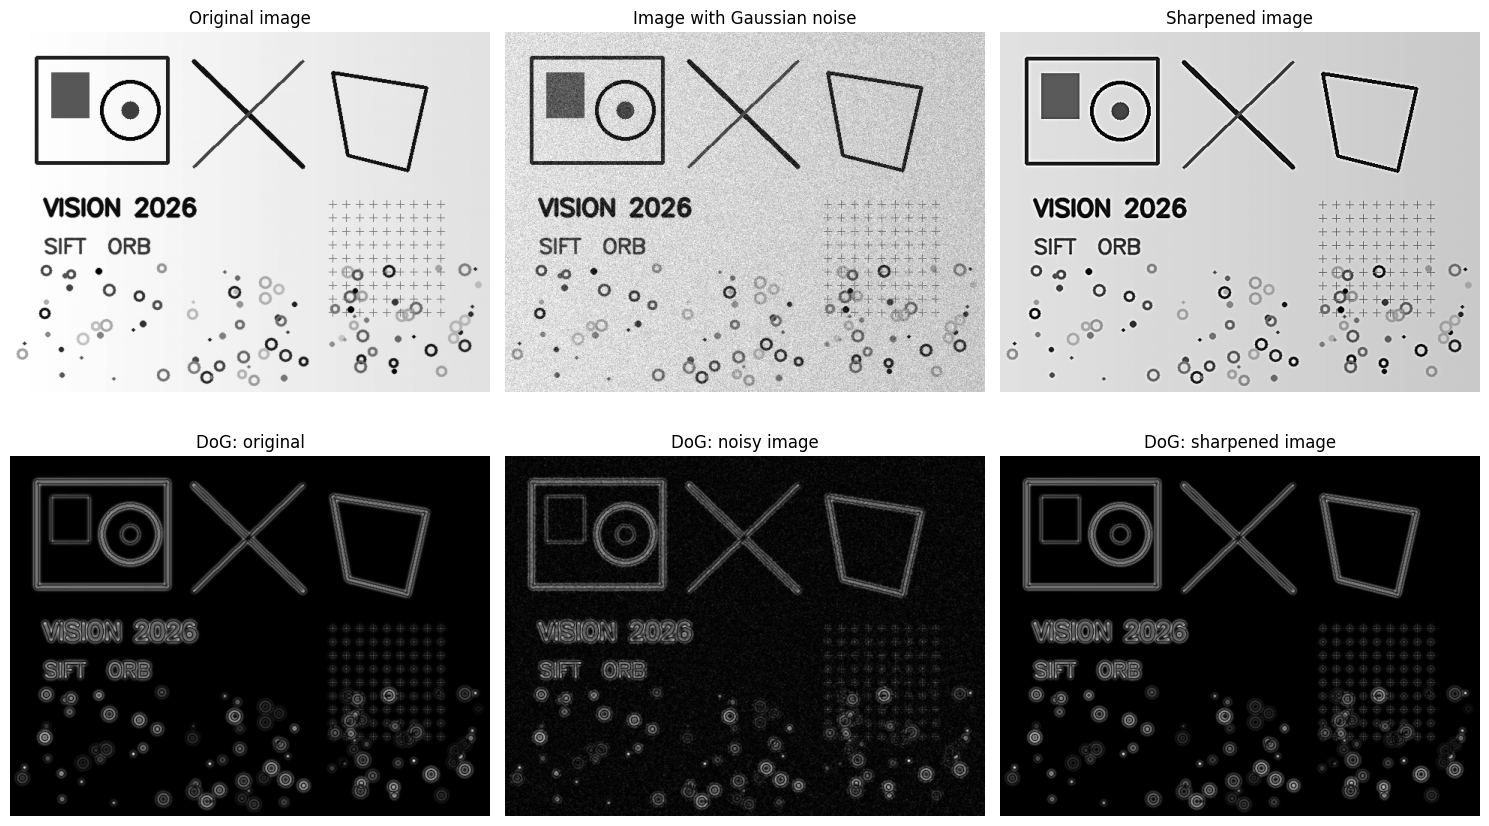

SIFT keypoints - original: 758
SIFT keypoints - noisy:    1261
SIFT keypoints - sharpened:802


In [4]:
# Bonus: compare DoG responses before and after preprocessing.
rng = np.random.default_rng(21)
noise = rng.normal(loc=0.0, scale=18.0, size=img.shape)
noisy_img = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

# Unsharp masking: original + a scaled detail layer.
soft_blur = cv2.GaussianBlur(img, (0, 0), sigmaX=2.0)
sharpened_img = cv2.addWeighted(img, 1.5, soft_blur, -0.5, 0)

def get_dog_response(gray_image, sigma_small=1.0, sigma_large=2.0):
    small = cv2.GaussianBlur(gray_image, (0, 0), sigmaX=sigma_small)
    large = cv2.GaussianBlur(gray_image, (0, 0), sigmaX=sigma_large)
    difference = np.abs(small.astype(np.float32) - large.astype(np.float32))
    return cv2.normalize(difference, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

original_dog = get_dog_response(img)
noisy_dog = get_dog_response(noisy_img)
sharpened_dog = get_dog_response(sharpened_img)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
items = [
    (img, 'Original image'),
    (noisy_img, 'Image with Gaussian noise'),
    (sharpened_img, 'Sharpened image'),
    (original_dog, 'DoG: original'),
    (noisy_dog, 'DoG: noisy image'),
    (sharpened_dog, 'DoG: sharpened image'),
]
for ax, (image, title) in zip(axes.ravel(), items):
    ax.imshow(image, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Also compare how preprocessing changes the number of SIFT keypoints.
kp_original, _ = sift.detectAndCompute(img, None)
kp_noisy, _ = sift.detectAndCompute(noisy_img, None)
kp_sharp, _ = sift.detectAndCompute(sharpened_img, None)
print(f"SIFT keypoints - original: {len(kp_original)}")
print(f"SIFT keypoints - noisy:    {len(kp_noisy)}")
print(f"SIFT keypoints - sharpened:{len(kp_sharp)}")

**Bonus observations:**

- Adding Gaussian noise introduces small random intensity changes. These can appear as extra responses in the DoG image and may create additional, less meaningful keypoints. The noisy image can therefore contain more detected points without containing more useful visual information.
- Sharpening increases local contrast around boundaries, so some edges and details become more noticeable in the DoG response. This can help feature detection when the original image is slightly blurred.
- Strong sharpening can also amplify noise and create halos near edges. In that case it may add unstable features and make matching less reliable.

The printed SIFT counts show the effect for this particular image and preprocessing strength. A higher count does not automatically mean better detection or matching; the keypoints should be distinctive and repeatable across both images.

**Reflection:**

The most interesting part was seeing that edge detection, denoising, and feature detection solve different problems. DoG and LoG emphasize intensity changes, while the bilateral filter tries to remove noise and preserve boundaries. Comparing SIFT with ORB also showed that detecting many keypoints is not the same as finding the most useful matches. The ratio test and RANSAC were especially useful because they helped remove ambiguous and geometrically inconsistent matches.